# Can you trust the map? Auditing AI-generated local answers in one Paris district

**Scope:** Paris 11e (OSM relation 9533, INSEE 75111) · pharmacies, schools, addresses.
**PUBLIC DATA:** FINESS and Education registries, BAN geocoder, OpenStreetMap, Overture Maps, SIRENE (read 2026-11-22).
**SIMULATED:** 600 answers of a fictional local-search assistant (no LLM called) and 3 simulated annotators.
Desk research only. No place or person names are shown anywhere in this notebook.

Pipeline before this notebook: `fetch_public.py` → `simulate_assistant.py` → `run_sql.py` (sql/01-07) → `build_workbook.py`.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, duckdb
pd.set_option("display.width", 140)
P = Path("..") / "data" / "processed"
r = lambda f: pd.read_csv(P / f"{f}.csv")
places, audit = r("places"), r("audit_log")
print(places.shape, audit.shape)
places[places.in_11e == 1].groupby(["theme", "source"]).size().unstack(fill_value=0)

(976, 22) (600, 32)


source,EDU,FINESS,OSM,OVERTURE
theme,,,,
pharmacy,0,59,62,84
school,96,0,126,56


## 1. Sources: coverage inside the 11e (PUBLIC DATA)

In [2]:
r("coverage").pivot_table(index=["theme", "category"], columns="source", values="n", aggfunc="sum", fill_value=0)

source                              EDU  FINESS  OSM  OVERTURE
theme    category                                             
pharmacy drugstore                    0       0    2         3
         medical_supply               0       0    2         0
         pharmacy                     0      59   58        81
school   higher_or_adult_education    0       0   29         0
         kindergarten_or_nursery      0       0   37         0
         other_education             12       0    0         0
         school                      55       0   60        43
         secondary_school            29       0    0        13

## 2. Event 9, the false signal: does Overture invent pharmacies?
The first count suggests Overture holds about 5 times more pharmacies than OSM. Recount with the same area, the same category definition and the same status.

In [3]:
fs = r("false_signal"); fs

,step,definition,overture,osm,finess
0,1,First count: Overture download box (wider than...,300,56,59
1,2,Same area: only places inside the 11e polygon,84,56,59
2,3,Same category: taxonomy = pharmacy (drugstores...,81,56,59
3,4,Same status: open places only (permanently clo...,60,56,59


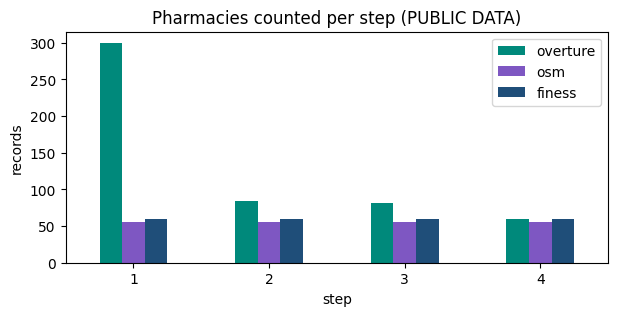

In [4]:
ax = fs.set_index("step")[["overture", "osm", "finess"]].plot.bar(figsize=(7, 3), color=["#00897b", "#7e57c2", "#1f4e79"], rot=0)
ax.set_title("Pharmacies counted per step (PUBLIC DATA)"); ax.set_ylabel("records"); plt.show()

**Conclusion:** at step 4 Overture has 60 open pharmacies, OSM 56 and FINESS 59. The gap came from the download box (wider than the district) and from a category filter that caught drugstores and closed places. **Not reported as a data defect.**

## 3. Matching across sources (distance + name similarity)

In [5]:
ms = r("matching_summary"); ms

,theme,source,other_source,records,matched,pct_matched,median_dist_m
0,pharmacy,FINESS,OSM,59,56,94.9,4.5
1,pharmacy,FINESS,OVERTURE,59,53,89.8,1.6
2,pharmacy,OSM,FINESS,56,55,98.2,4.5
3,pharmacy,OSM,OVERTURE,56,52,92.9,5.9
4,pharmacy,OVERTURE,FINESS,77,61,79.2,2.4
5,pharmacy,OVERTURE,OSM,77,59,76.6,5.9
6,school,EDU,OSM,84,52,61.9,15.6
7,school,EDU,OVERTURE,84,37,44.0,9.9
8,school,OSM,EDU,60,38,63.3,16.5
9,school,OSM,OVERTURE,60,21,35.0,19.5


In [6]:
reg = r("registry_missing_in_open")
reg.groupby(["in_osm", "in_overture"]).size().rename("registry pharmacies")

in_osm  in_overture
False   False           2
        True            1
True    False           4
        True           52
Name: registry pharmacies, dtype: int64

## 4. Event 6 (real data-quality issue): the same pharmacy twice across sources

In [7]:
xd = r("cross_source_duplicates")
print(len(xd), "OSM-Overture pairs of the same pharmacy with different names; median distance", xd.dist_m.median(), "m")
xd.describe()[["dist_m", "name_sim"]].round(2)

22 OSM-Overture pairs of the same pharmacy with different names; median distance 6.4 m


,dist_m,name_sim
count,22.00,22.00
mean,7.26,0.49
std,5.43,0.19
min,2.70,0.00
25%,4.12,0.41
50%,6.40,0.51
75%,7.88,0.59
max,29.00,0.79


## 5. Event 7 (real data-quality issue): registry lag. Is 'absent from FINESS' the same as 'invented'?

In [8]:
nir = r("not_in_registry")
nir.assessment.value_counts()

assessment
probable pin offset of a registry pharmacy          6
cannot verify (desk research only)                  4
confirmed by a second source                        2
likely stale: ceased SIRENE establishment nearby    1
Name: count, dtype: int64

In [9]:
nir.drop(columns=["place_id"]).sort_values("nearest_finess_m")

,source,confidence,nearest_finess_m,other_open_source,nearest_sirene_active_m,nearest_sirene_ceased_m,assessment
4,OVERTURE,0.956,44.0,False,44.0,249.0,confirmed by a second source
0,OSM,NaN,46.0,True,49.0,49.0,confirmed by a second source
7,OVERTURE,0.500,63.0,False,81.0,81.0,probable pin offset of a registry pharmacy
1,OVERTURE,0.500,69.0,False,70.0,310.0,probable pin offset of a registry pharmacy
12,OVERTURE,0.973,69.0,False,70.0,310.0,probable pin offset of a registry pharmacy
2,OVERTURE,0.947,74.0,False,74.0,150.0,probable pin offset of a registry pharmacy
10,OVERTURE,0.500,92.0,False,79.0,334.0,probable pin offset of a registry pharmacy
6,OVERTURE,0.759,102.0,False,102.0,206.0,probable pin offset of a registry pharmacy
11,OVERTURE,0.508,126.0,False,125.0,125.0,cannot verify (desk research only)
9,OVERTURE,0.770,134.0,False,133.0,202.0,cannot verify (desk research only)


Most gaps are pins 63-102 m from a registry pharmacy (probable offsets), two are confirmed by a second source, one looks stale (ceased SIRENE establishment 27 m away), four cannot be settled from the desk. SIRENE shows no 47.73Z establishment created or ceased in the 11e after the FINESS extraction (2026-05-04). **Rule:** absent from the registry ≠ false without a second source.

## 6. Position drift: pin vs BAN geocode of the record's own address

In [10]:
r("drift_summary")

,source,geocoded,median_m,p90_m,over_150m,bis_ter_addresses,bis_ter_over_150m
0,EDU,95,0.0,0.1,0.0,4.0,0.0
1,FINESS,204,0.0,0.1,0.0,5.0,0.0
2,OSM,41,6.5,40.0,0.0,1.0,0.0
3,OVERTURE,467,2.9,19.8,9.0,6.0,0.0


Registry coordinates sit on the BAN point (median 0 m). No real bis / ter address drifts 150 m or more, so event 3 below is purely simulated.

## 7. Automatic checks on the 600 SIMULATED answers (events 1-5, 8)

In [11]:
audit.auto_code.value_counts().to_frame("answers").assign(pct=lambda d: (100 * d.answers / 600).round(1))

,answers,pct
auto_code,,
PASS,399,66.5
MISSING_HOURS,40,6.7
CLOSED_PLACE,37,6.2
WRONG_CATEGORY,24,4.0
POSITION_DRIFT,24,4.0
OUT_OF_AREA,24,4.0
NOT_IN_REGISTRY,18,3.0
DUPLICATE,18,3.0
NOT_FOUND,16,2.7


In [12]:
r("error_rates")

,query_type,answers,flagged,pct_flagged
0,address_lookup,150,24.0,16.0
1,category_search,120,53.0,44.2
2,find_nearest,190,50.0,26.3
3,opening_status,140,56.0,40.0


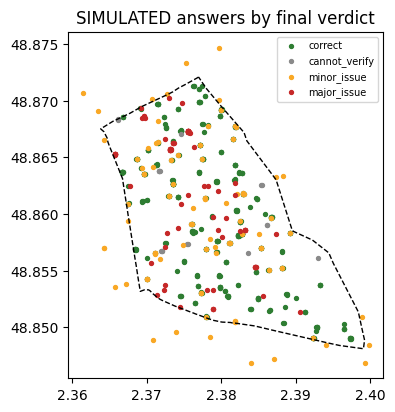

In [13]:
fig, ax = plt.subplots(figsize=(5, 4.5))
for v, col in {"correct": "#2e7d32", "cannot_verify": "#8a8a8a", "minor_issue": "#f9a825", "major_issue": "#c62828"}.items():
    s = audit[audit.final_verdict == v]; ax.scatter(s.shown_lon, s.shown_lat, s=8, color=col, label=v)
import json
gj = json.load(open(P / "boundary_11e.geojson"))
for poly in gj["geometry"]["coordinates"]:
    xs, ys = zip(*poly[0]); ax.plot(xs, ys, "k--", lw=1)
ax.set_aspect(1 / 0.657); ax.set_title("SIMULATED answers by final verdict"); ax.legend(fontsize=7); plt.show()

### The events, one by one (each found by its own check)

In [14]:
events = {
 "1 closed place recommended": "CLOSED_PLACE", "2 invented place": "NOT_FOUND", "3 position drift (bis/ter)": "POSITION_DRIFT",
 "4 wrong category": "WRONG_CATEGORY", "5 outside the 11e": "OUT_OF_AREA", "8 missing hours (grey zone)": "MISSING_HOURS",
 "6 duplicate in the answer": "DUPLICATE", "7 not in registry": "NOT_IN_REGISTRY"}
pd.DataFrame({"auto_code": events, "answers": {k: int((audit.auto_code == v).sum()) for k, v in events.items()},
              "example": {k: audit.loc[audit.auto_code == v, "answer_id"].iloc[0] for k, v in events.items()}})

,auto_code,answers,example
1 closed place recommended,CLOSED_PLACE,37,A0013
2 invented place,NOT_FOUND,16,A0032
3 position drift (bis/ter),POSITION_DRIFT,24,A0017
4 wrong category,WRONG_CATEGORY,24,A0003
5 outside the 11e,OUT_OF_AREA,24,A0042
8 missing hours (grey zone),MISSING_HOURS,40,A0023
6 duplicate in the answer,DUPLICATE,18,A0040
7 not in registry,NOT_IN_REGISTRY,18,A0028


In [15]:
# Event 3: bis / ter pins
d = audit[audit.auto_code == "POSITION_DRIFT"]
print(d.shown_address.str.contains(r"\d+[BT] ", regex=True).mean().round(2), "share of drift answers on bis/ter numbers")
d.pin_vs_ban_m.describe().round(0)

1.0 share of drift answers on bis/ter numbers


count     24.0
mean     298.0
std       75.0
min      164.0
25%      231.0
50%      310.0
75%      361.0
max      401.0
Name: pin_vs_ban_m, dtype: float64

## 8. Answer key (SIMULATED), opened only now, after the checks ran

In [16]:
truth = pd.read_csv(Path("..") / "data" / "_hidden_truth.csv").dropna(subset=["answer_id"])
m = audit.merge(truth, on="answer_id")
pd.crosstab(m.true_code.fillna("(clean)"), m.auto_code)

auto_code,CLOSED_PLACE,DUPLICATE,MISSING_HOURS,NOT_FOUND,NOT_IN_REGISTRY,OUT_OF_AREA,PASS,POSITION_DRIFT,WRONG_CATEGORY
true_code,,,,,,,,,
(clean),0,0,0,0,0,0,398,0,0
CLOSED_PLACE,36,0,0,0,0,0,0,0,0
DUPLICATE,0,18,0,0,0,0,0,0,0
INVENTED_PLACE,1,0,0,16,0,0,1,0,0
MISSING_HOURS,0,0,40,0,0,0,0,0,0
NOT_IN_REGISTRY,0,0,0,0,18,0,0,0,0
OUT_OF_AREA,0,0,0,0,0,24,0,0,0
POSITION_DRIFT,0,0,0,0,0,0,0,24,0
WRONG_CATEGORY,0,0,0,0,0,0,0,0,24


In [17]:
issues = m[m.true_code.notna() & (m.true_code != "NOT_IN_REGISTRY")]      # planted errors (event 7 is not an error)
caught = (issues.true_code.replace({"INVENTED_PLACE": "NOT_FOUND"}) == issues.auto_code).sum()
print(f"planted issues with the right code: {caught} / {len(issues)}")
lag = m[m.true_code == "NOT_IN_REGISTRY"]
print("registry-lag answers flagged NOT_IN_REGISTRY:", int((lag.auto_code == "NOT_IN_REGISTRY").sum()), "/", len(lag))
print("verdict agreement, rubric vs answer key:", round((m.final_verdict == m.true_verdict).mean(), 3))
print("false alarms on clean answers:", int(((m.true_code.isna()) & (m.auto_code != "PASS")).sum()))

planted issues with the right code: 182 / 184
registry-lag answers flagged NOT_IN_REGISTRY: 18 / 18
verdict agreement, rubric vs answer key: 0.998
false alarms on clean answers: 0


The two misses are invented places: one sits at an address that really hosts a pharmacy (every automatic check passes; only reading the name catches it), the other next to a closed record. Recall is optimistic because the same person designed the errors and the checks.

## 9. Event 8: annotator agreement, before and after guidelines v2 (SIMULATED)

In [18]:
agr = r("agreement")
agr.pivot_table(index=["scope", "pair"], columns="guidelines_version", values="cohen_kappa")

guidelines_version            v1     v2
scope               pair               
all answers         R1-R2  0.581  0.834
                    R1-R3  0.602  0.822
                    R2-R3  0.636  0.809
opening_status only R1-R2  0.426  0.853
                    R1-R3  0.528  0.783
                    R2-R3  0.549  0.785

In [19]:
# Cohen's kappa recomputed in pandas for one pair, as a cross-check of the SQL
ann = r("annotations")
def kappa(a, b):
    po = (a == b).mean(); cats = set(a) | set(b)
    pe = sum((a == c).mean() * (b == c).mean() for c in cats); return (po - pe) / (1 - pe)
for v in ("v1", "v2"):
    w = ann[ann.guidelines_version == v].pivot(index="answer_id", columns="annotator_id", values="verdict")
    print(v, "R1-R2 kappa =", round(kappa(w.R1, w.R2), 3))

v1 R1-R2 kappa = 0.581
v2 R1-R2 kappa = 0.834


In [20]:
r("confusion_r1_r2")

,guidelines_version,r1_verdict,r2_correct,r2_minor_issue,r2_major_issue,r2_cannot_verify
0,v1,correct,175.0,11.0,9.0,5.0
1,v1,minor_issue,12.0,27.0,24.0,0.0
2,v1,major_issue,0.0,6.0,37.0,1.0
3,v1,cannot_verify,1.0,0.0,2.0,0.0
4,v2,correct,182.0,5.0,0.0,4.0
5,v2,minor_issue,5.0,37.0,1.0,1.0
6,v2,major_issue,0.0,5.0,39.0,0.0
7,v2,cannot_verify,4.0,0.0,0.0,7.0


In [21]:
ann.groupby("guidelines_version").seconds.median()

guidelines_version
v1    79.0
v2    65.0
Name: seconds, dtype: float64

## 10. Recommendations
1. Geocode first (BAN house number): it settles position and area in seconds.
2. Never call a place invented from one source: absent from the registry → second source, else *cannot verify*.
3. Compare like with like before raising a source issue (area, category, status): see the false signal.
4. Write explicit rules for grey zones (missing hours, registry gaps, distance thresholds): they drive disagreement.
5. Keep a human on the name: an invented place at a real address passes every automatic check.

*Independent case study based on public data · not affiliated with or endorsed by any AI or mapping company.*